=== MÉTRIQUES CALCULÉES ===
Femmes - Accuracy: 0.9295, Recall: 0.9693, F1-Score: 0.9377
Hommes - Accuracy: 0.8317, Recall: 0.6941, F1-Score: 0.7763
Disparité d'Exactitude (Accuracy Discrepancy) : 0.0978

Graphique sauvegardé avec succès sous : c:\Users\babacar\tp2_ethics\outputs\figures\metrics_biased_model.png


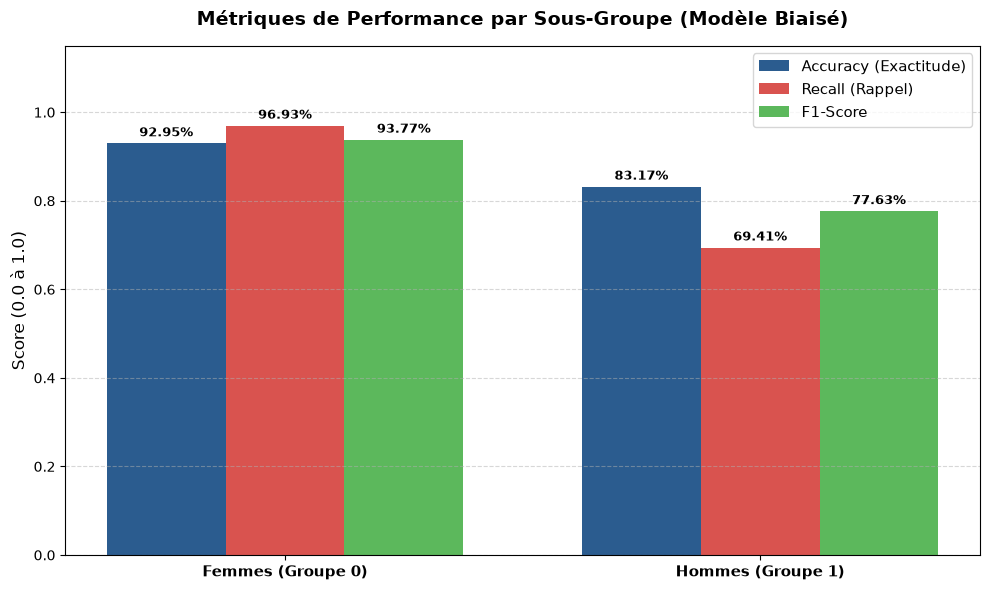

In [7]:
import sys
import os

# 1. Configuration du chemin d'accès vers la racine du projet (tp2_ethics)
project_root = os.path.abspath(os.path.join('..', '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from src.dataset import CustomCelebADataset, get_default_transforms
from src.model import build_resnet50
from src.bias_analysis import evaluate_bias

# 2. Emplacement des fichiers (chemins relatifs par rapport à la racine)
txt_path = os.path.join(project_root, "data", "list_attr_celeba_500.txt")
img_dir = os.path.join(project_root, "data", "images")
model_path = os.path.join(project_root, "outputs", "models", "resnet50_base_biased.pth")

# 3. Chargement du dataset et préparation du DataLoader
dataset = CustomCelebADataset(txt_file=txt_path, img_dir=img_dir, transform=get_default_transforms())
eval_dataloader = DataLoader(dataset, batch_size=16, shuffle=False)

target_idx = dataset.attr_names.index("Smiling") if "Smiling" in dataset.attr_names else 31
sensitive_idx = dataset.attr_names.index("Male") if "Male" in dataset.attr_names else 20

# 4. Chargement du modèle biaisé entraîné
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = build_resnet50(num_classes=2)
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device)

# 5. Évaluation des biais par sous-groupe
metrics, disc_acc, disc_rec = evaluate_bias(model, eval_dataloader, target_idx, sensitive_idx, device=device)

# Extraction des métriques pour chaque groupe
groups = ['Femmes (Groupe 0)', 'Hommes (Groupe 1)']
accs = [metrics[0]['Accuracy'], metrics[1]['Accuracy']]
recalls = [metrics[0]['Recall'], metrics[1]['Recall']]
f1s = [metrics[0]['F1-Score'], metrics[1]['F1-Score']]

print("=== MÉTRIQUES CALCULÉES ===")
print(f"Femmes - Accuracy: {accs[0]:.4f}, Recall: {recalls[0]:.4f}, F1-Score: {f1s[0]:.4f}")
print(f"Hommes - Accuracy: {accs[1]:.4f}, Recall: {recalls[1]:.4f}, F1-Score: {f1s[1]:.4f}")
print(f"Disparité d'Exactitude (Accuracy Discrepancy) : {disc_acc:.4f}")

# 6. Affichage des histogrammes de comparaison avec Matplotlib
x = np.arange(len(groups))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width, accs, width, label='Accuracy (Exactitude)', color='#2b5c8f')
rects2 = ax.bar(x, recalls, width, label='Recall (Rappel)', color='#d9534f')
rects3 = ax.bar(x + width, f1s, width, label='F1-Score', color='#5cb85c')

ax.set_ylabel('Score (0.0 à 1.0)', fontsize=12)
ax.set_title('Métriques de Performance par Sous-Groupe (Modèle Biaisé)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Ajout des valeurs numériques au-dessus des barres
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2%}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()

# Sauvegarde de la figure dans le dossier outputs/figures/
fig_save_path = os.path.join(project_root, "outputs", "figures", "metrics_biased_model.png")
os.makedirs(os.path.dirname(fig_save_path), exist_ok=True)
plt.savefig(fig_save_path, dpi=300)
print(f"\nGraphique sauvegardé avec succès sous : {fig_save_path}")

plt.show()

Courbe d'évolution sauvegardée sous : c:\Users\babacar\tp2_ethics\outputs\figures\loss_evolution.png


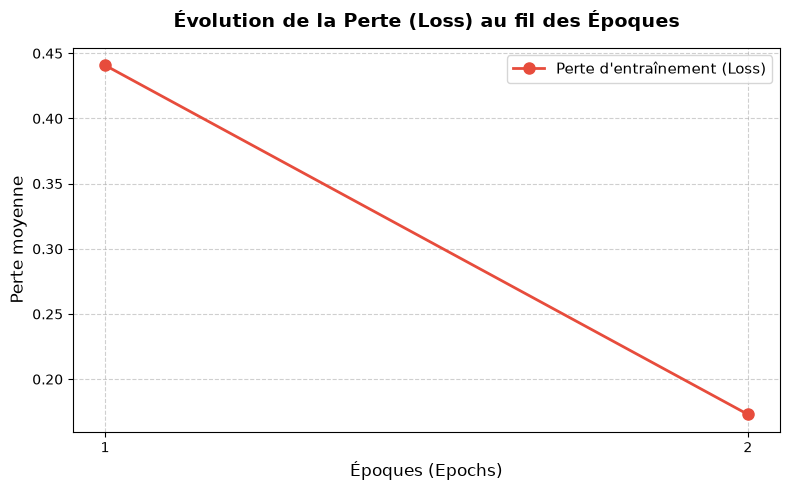

In [8]:
import matplotlib.pyplot as plt

# Exemple d'historique de perte récupéré lors de l'entraînement
# (Vous pouvez adapter ces listes avec vos propres valeurs d'époques)
epochs = [1, 2]
train_losses = [0.4408, 0.1730]  # Vos pertes relevées lors de l'entraînement

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker='o', linestyle='-', color='#e74c3c', linewidth=2, markersize=8, label='Perte d\'entraînement (Loss)')

plt.title('Évolution de la Perte (Loss) au fil des Époques', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Époques (Epochs)', fontsize=12)
plt.ylabel('Perte moyenne', fontsize=12)
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()

# Sauvegarde de la courbe
import os
fig_save_path = os.path.join(project_root, "outputs", "figures", "loss_evolution.png")
os.makedirs(os.path.dirname(fig_save_path), exist_ok=True)
plt.savefig(fig_save_path, dpi=300)
print(f"Courbe d'évolution sauvegardée sous : {fig_save_path}")

plt.show()